In [1]:
import os
import os.path as op

import matplotlib.pyplot as plt

import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning')

import neuron
from neuron import h
import hnn_core
from hnn_core.params import _short_name

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod'
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'


import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/utils')
from cell_builder_utils import l5_params, _get_dends, _get_pyr_soma, Cell, l2_params
from l5_mechs_utils import Mechs, Ih_condu_hay, linear_gbar
from functools import partial
import os
from hnn_core.viz import plot_cell_morphology

# The number of cores may need modifying depending on your current machine.
n_procs = 10
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'

# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels

150.6591337099859
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/dipole.py:76: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn(


(0.0, 120.0)

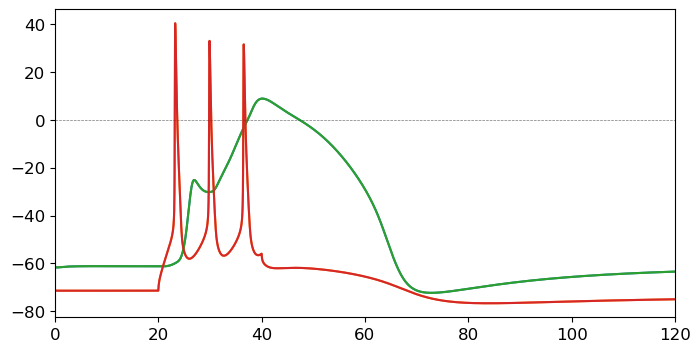

In [2]:
model_params = {'soma': {'NaTs2_t': 20_400e-4/2*1.5,
                                'SKv3_1': 6_930e-4/2,
                                'Nap_Et2': 17.2e-4/2*0.11,
                                'Ca_HVA': 9.92e-04/2,
                                'Ca_LVAst': 34.3e-4/2,
                                'SK_E2': 441e-4*15,                      # increase this one to get burst followed by regular firing
                                'Ih': 1e-4/2,
                                'Im': 1e-4,
                                'K_Pst': 22.3e-4/2,#*0.1,
                                'K_Tst': 812e-4/2,#*0.1,
                                'pas': {'g': .338e-4/2/2,
                                          'e': -90}},
                        'basal': {'NaTs2_t': partial(linear_gbar,0.0102,0,255),
                                'SKv3_1': partial(linear_gbar,0,0.0001305,255),
                                  'Ih': 5.14e-5/4*2,
                                  'pas': {'g': 1.75e-5/2*3,
                                          'e': -90}},
                        'dend': {'NaTa_t': 0.0213/2,
                                'SKv3_1': 0.000261/2*2,
                                'Ca_HVA': partial(linear_gbar, 2.78e-5/2., 2.78e-5/2*12.0, 1500, hotzone=[1500, 1700], hotzone_factor=4.5),
                                'Ca_LVAst': partial(linear_gbar, 93.5e-6/2, 93.5e-6/2*2.25, 1500, hotzone=[1500, 1700], hotzone_factor=2.25),
                                'SK_E2': 0.0012/2*6,#*2,#*1.6,
                                'Ih': partial(Ih_condu_hay, 1e-4/2*1.2),   
                                'Im': 0.0000675/2,
                                'K_Pst': 0,
                                'K_Tst': 0,
                                'pas': {'g': 0.0000589/1.5,
                                          'e': -85}}}
hotzone = [1500, 1700]

# get paramaters
section_params, end_pts, cell_tree = l5_params()

# build sections
section_names = list(end_pts.keys())

v_init = {'soma': -71.56521022702259,
        'basal_1': -71.65128168943417,
        'basal_2': -71.77924562640379,
        'basal_3': -71.77924562640379,
        'apical_oblique': -71.53636973768913,
        'apical_trunk': -71.50652549683365,
        'apical_1': -70.3781183764456,
        'apical_2': -66.1535511211922,
        'apical_tuft': -61.47225400606895}

sections = _get_dends(section_params, 'L5Pyr', section_names, end_pts, v_init=v_init)
sections['soma'] = _get_pyr_soma(section_params, 'L5Pyr', end_pts['soma'], v_init=v_init['soma'])

mech_class = Mechs(pth_mod)



l5pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()

l5pyr = mech_class.add_mechs(l5pyr, model_params, hotzone=hotzone)

voltg = [None]*2
t = h.Vector().record(h._ref_t)
stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 20
stim.dur = 20
stim.amp = 3


voltg[1] = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

voltg[0] = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(120)

# find frequency
from scipy.signal import find_peaks
start = np.argmin(np.abs(t.as_numpy() - stim.delay))
stop = np.argmin(np.abs(t.as_numpy() - (stim.delay+stim.dur)))
pk = find_peaks(voltg[1].as_numpy()[start:stop], height=0)[0]
freq = stim.dur/np.mean(np.abs(np.diff(t.as_numpy()[pk])))*1000/stim.dur
print(freq)

# clamp_current = np.zeros_like(t.as_numpy())
# for i in range(num_pulse):
#     clamp_current[(t.as_numpy() > stim[i].delay) & (t.as_numpy() < stim[i].delay+stim[i].dur)] = stim[i].amp

clamp_current = np.zeros_like(t.as_numpy())
clamp_current[(t.as_numpy() > stim.delay) & (t.as_numpy() < stim.delay+stim.dur)] = stim.amp

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
for s, section in enumerate(['apical_2', 'soma']):
    ax.axhline(y=0, color='black', alpha=0.2, linewidth=0.5, linestyle='--')
    ax.plot(t, voltg[s])

v_soma = voltg[1].as_numpy().copy()
v_apcl = voltg[0].as_numpy().copy()

distance_apical = []
gbar_Ih_apical = []
gbar_Ca_HVA_apical = []
gbar_Ca_LVA_apical = []

apical_sections=['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
h.distance(sec = l5pyr._nrn_sections['soma'])
for section in apical_sections:
    for seg in l5pyr._nrn_sections[section]:
        distance_apical.append(h.distance(seg.x, sec=seg.sec))
        gbar_Ih_apical.append(seg.gbar_Ih)
        gbar_Ca_HVA_apical.append(seg.gbar_Ca_HVA)
        gbar_Ca_LVA_apical.append(seg.gbar_Ca_LVAst)

h('forall delete_section()')

net = duecker_ET_model(mesh_shape=(1,1))
net.clear_connectivity()
net.add_tonic_bias(cell_type='L5_pyramidal', section='soma', bias_name='clamp', amplitude=3, t0=20, tstop = 40)
dpl = simulate_dipole(net, tstop=120, bsl_cor='calcium', record_vsec='all', record_ca='all', record_isec='all')

ax.plot(np.array(net.cell_response.times), np.array(net.cell_response.vsec[0][3]['apical_tuft']))
ax.plot(np.array(net.cell_response.times), np.array(net.cell_response.vsec[0][3]['soma']))
ax.axhline(y=0, color='black', alpha=0.2, linewidth=0.5, linestyle='--')
ax.set_xlim((0, 120))



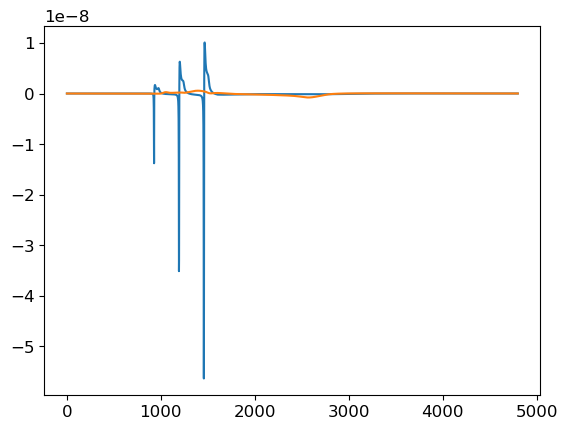

In [3]:
plt.plot(np.array(net.cell_response.vsec[0][3]['soma'])-v_soma)
plt.plot(np.array(net.cell_response.vsec[0][3]['apical_tuft'])-v_apcl)

In [4]:
L = net.cell_types['L5_pyramidal']['cell_object'].sections['soma'].L
distance_HNN = []
Ih = []
CHVA = []
CLVA = []

apical_sections=['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
for section in apical_sections:
    for s, seg in enumerate(net.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][0]):
        distance_HNN.append(float(L+net.cell_types['L5_pyramidal']['cell_object'].sections[section].L*seg))
        Ih.append(net.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ih']['gbar_Ih'][1][s])
        CHVA.append(net.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1][s])
        CLVA.append(net.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1][s])

    L += net.cell_types['L5_pyramidal']['cell_object'].sections[section].L


<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\m'
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_52746/2985569708.py:5: SyntaxWarning: invalid escape sequence '\m'
  ax[0].set_xlabel('distance to soma ($\mu m$)')
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_52746/2985569708.py:9: SyntaxWarning: invalid escape sequence '\m'
  ax[1].set_xlabel('distance to soma ($\mu m$)')
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_52746/2985569708.py:13: SyntaxWarning: invalid escape sequence '\m'
  ax[2].set_xlabel('distance to soma ($\mu m$)')


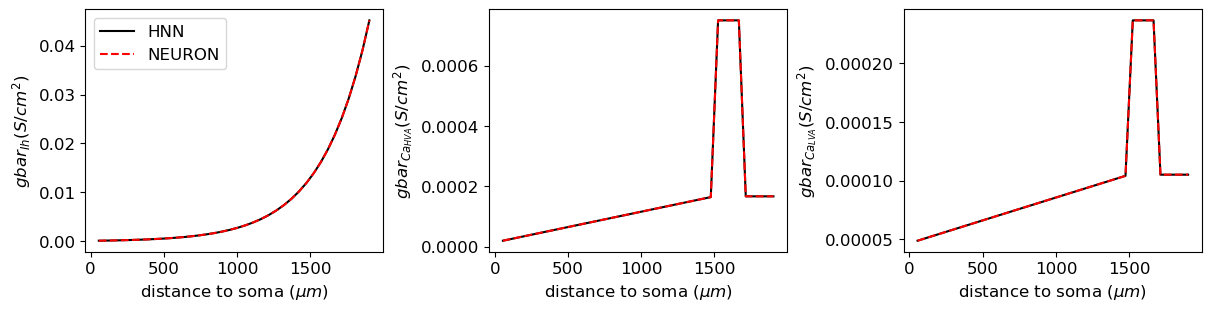

In [5]:


fig, ax = plt.subplots(1, 3, figsize=(12, 3), constrained_layout=True)
ax[0].plot(distance_HNN, Ih, color='k', label='HNN')
ax[0].plot(distance_apical, gbar_Ih_apical, color='r', linestyle='--', label='NEURON')
ax[0].set_ylabel('$gbar_{Ih} (S/cm^2)$')
ax[0].set_xlabel('distance to soma ($\mu m$)')
ax[1].plot(distance_HNN, CHVA, color='k', label='HNN')
ax[1].plot(distance_apical, gbar_Ca_HVA_apical, color='r', linestyle='--', label='NEURON')
ax[1].set_ylabel('$gbar_{Ca_{HVA}} (S/cm^2)$')
ax[1].set_xlabel('distance to soma ($\mu m$)')
ax[2].plot(distance_HNN, CLVA, color='k', label='HNN')
ax[2].plot(distance_apical, gbar_Ca_LVA_apical, color='r', linestyle='--', label='NEURON')
ax[2].set_ylabel('$gbar_{Ca_{LVA}} (S/cm^2)$')
ax[2].set_xlabel('distance to soma ($\mu m$)')
ax[0].legend()


In [6]:

#ax[1,1].set_xlim((15, 35))

In [7]:
# Interneuron